In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.multitest import fdrcorrection as fdr

In [3]:
df_PD = pd.read_csv('~/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_PD_cell_counts_no_SWM.csv')
df_CT = pd.read_csv('~/MinaRyten/Melissa/MRIxST/stats/02c-4layers_qMRIvsST_withendo_with_PrD/LOO_predictions_control_qMRI_vs_cell_count_no_SWM.csv')
df_control = pd.read_csv('~/MinaRyten/Melissa/MRIxST/processed_data/01b-4layers_withendo/02-top3_cells_counts/top3_cells_per_layer_count.csv', index_col = 0)

In [4]:
df_control['region'] = df_control['sample_id'].str.split('_', expand = True)[1]
df_control = df_control.groupby(['bayesSpace_harmony_7', 'variable', 'region']).median()
df_control.reset_index(inplace = True)
df_control.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)

In [5]:
df_CT = pd.melt(df_CT, id_vars=['SpD', 'region'], value_vars=['Astro_predicted', 'Micro_predicted', 'Oligo_predicted', 'OPC_predicted'])
df_CT['celltype'] = df_CT['variable'].str.split('_', expand = True)[0]
df_CT.rename(columns = { 'value':'Control - predicted counts'}, inplace = True)

In [6]:
df_PD = pd.melt(df_PD, id_vars=['SpD', 'region'], value_vars=['Astro_PD_predicted', 'Micro_PD_predicted', 'Oligo_PD_predicted', 'OPC_PD_predicted'])
df_PD['celltype'] = df_PD['variable'].str.split('_', expand = True)[0]
df_PD.rename(columns = { 'value':'PD - predicted counts'}, inplace = True)

In [7]:
df_control.rename(columns = {'bayesSpace_harmony_7':'SpD', 'variable':'celltype', 'value':'Control - real counts'}, inplace = True)
df_control = df_control[df_control['SpD']!='WM']
df_control['key'] = df_control['SpD']+df_control['celltype']+df_control['region']

In [8]:
df_PD = df_PD[['SpD','celltype','region', 'PD - predicted counts']]
df_PD['key'] = df_PD['SpD']+df_PD['celltype']+df_PD['region']

df_CT = df_CT[['SpD','celltype','region', 'Control - predicted counts']]
df_CT['key'] = df_CT['SpD']+df_CT['celltype']+df_CT['region']

In [9]:
#df = pd.concat([df_control, df_PD])

combined_PD = df_PD.merge(df_control[['key', 'Control - real counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined_PD.drop(columns = 'key', inplace = True)

combined_CT = df_CT.merge(df_control[['key', 'Control - real counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined_CT.drop(columns = 'key', inplace = True)

Cell type: Astro
R²: 0.8111395065487415
p-value: 6.443902790382335e-05


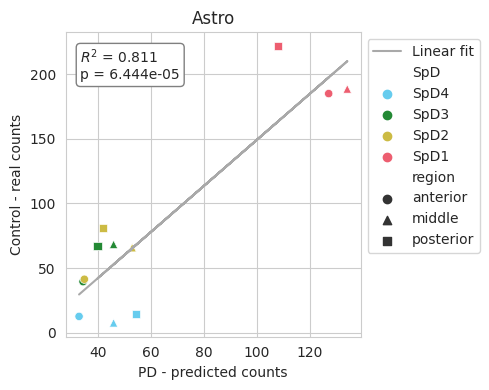

Cell type: Micro
R²: 0.5440192440290901
p-value: 0.006183643163161248


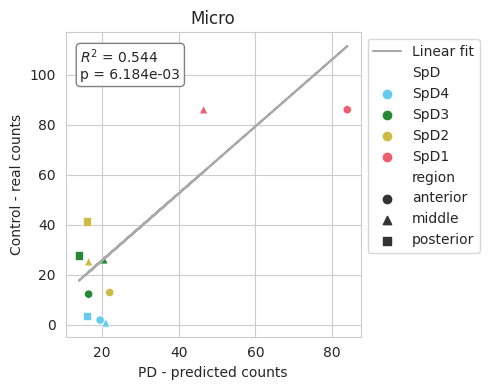

Cell type: Oligo
R²: 0.13722324416741583
p-value: 0.23588383896812734


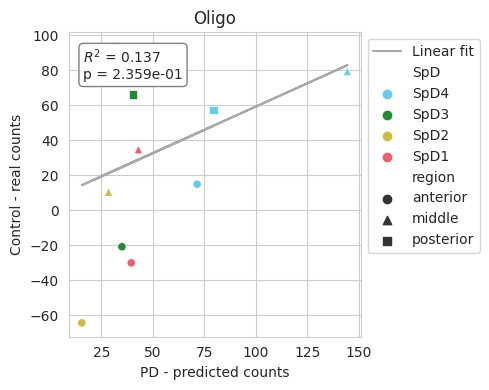

Cell type: OPC
R²: 0.4684913620931219
p-value: 0.014072256604670689


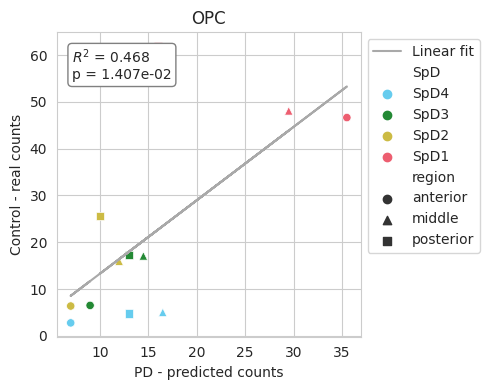

In [10]:
custom_palette = {
    'SpD1': '#ED5E70',  
    'SpD2': '#CCBB44',  
    'SpD3': '#238934',  
    'SpD4': '#66CCEE'   
}

custom_palette_CT = {
    'SpD1': '#e8bec4',  # blue
    'SpD2': '#e8e1ae',  # orange
    'SpD3': '#b2bfb4',  # green
    'SpD4': '#c2e2ed'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined_PD['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined_PD[combined_PD['celltype'] == cell]
    Y = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    X = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(y=df["PD - predicted counts"], x=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])

Cell type: Astro
R²: 0.4826806112774923
p-value: 0.014072256604670689


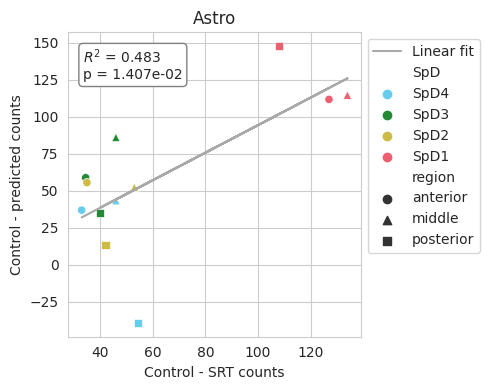

Cell type: Micro
R²: 0.54845523376275
p-value: 0.014072256604670689


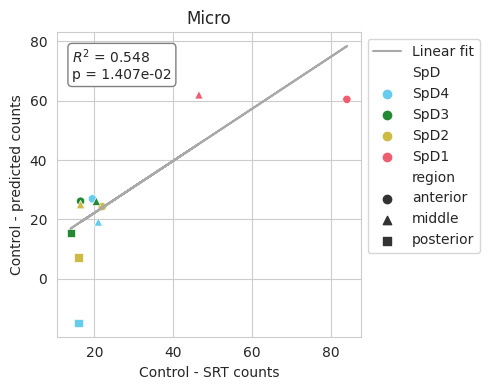

Cell type: Oligo
R²: 0.33413769669397275
p-value: 0.014072256604670689


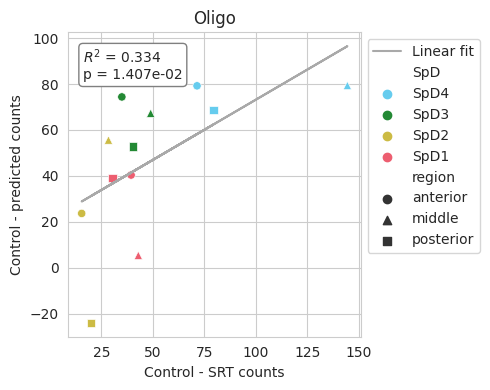

Cell type: OPC
R²: 0.33604027954999294
p-value: 0.014072256604670689


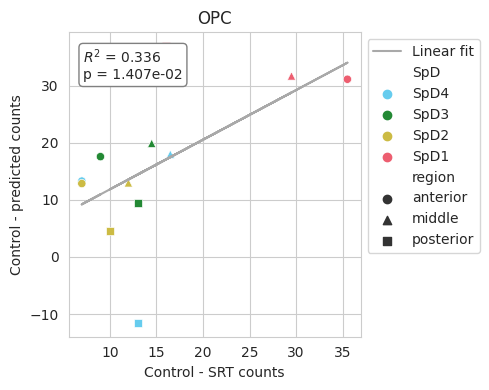

In [11]:
custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined_PD['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df_CT = combined_CT[combined_CT['celltype'] == cell]
    Y_CT = np.asarray(df_CT["Control - predicted counts"]).reshape(-1, 1)
    X_CT = np.asarray(df_CT["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model_CT = LinearRegression().fit(X_CT, Y_CT)
    
    # R² score
    r_squared_CT = model_CT.score(X_CT, Y_CT)
    print("R²:", r_squared_CT)
    
    
    # Add intercept
    X_sm_CT = sm.add_constant(X_CT)
    sm_model_CT = sm.OLS(Y_CT, X_sm).fit()
    p_value_CT = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value_CT)
    
    r2_text = f"$R^2$ = {r_squared_CT:.3f}"
    pval_text = f"p = {p_value_CT:.3e}"

    res.append(cell)
    res.append(r_squared_CT)
    res.append(p_value_CT)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X_CT, model_CT.predict(X_CT), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(y=df_CT["Control - predicted counts"], x=df_CT["Control - real counts"], hue=df_CT["SpD"], palette = custom_palette, style=df_CT["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.ylabel("Control - predicted counts")
    plt.xlabel("Control - SRT counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])

Cell type: Astro


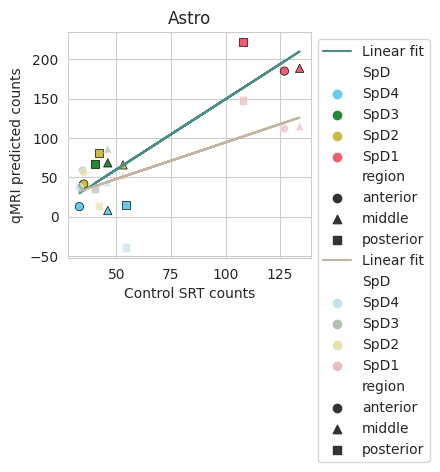

Astro | PD beta: 1.787, CT beta: 0.930
Z-test statistic: 2.096
                            OLS Regression Results                            
Dep. Variable:       Predicted counts   R-squared:                       0.719
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     17.02
Date:                Fri, 21 Nov 2025   Prob (F-statistic):           9.94e-06
Time:                        17:23:29   Log-Likelihood:                -117.76
No. Observations:                  24   AIC:                             243.5
Df Residuals:                      20   BIC:                             248.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

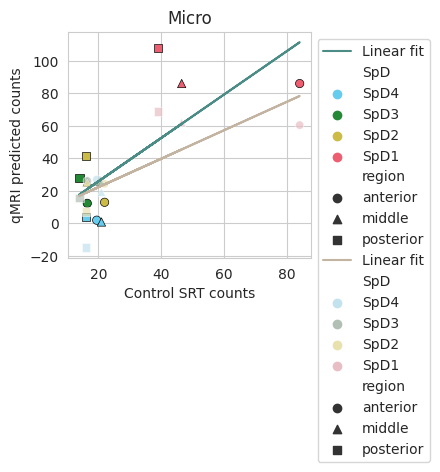

Micro | PD beta: 1.339, CT beta: 0.878
Z-test statistic: 0.998
                            OLS Regression Results                            
Dep. Variable:       Predicted counts   R-squared:                       0.552
Model:                            OLS   Adj. R-squared:                  0.484
Method:                 Least Squares   F-statistic:                     8.202
Date:                Fri, 21 Nov 2025   Prob (F-statistic):           0.000934
Time:                        17:23:30   Log-Likelihood:                -106.14
No. Observations:                  24   AIC:                             220.3
Df Residuals:                      20   BIC:                             225.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

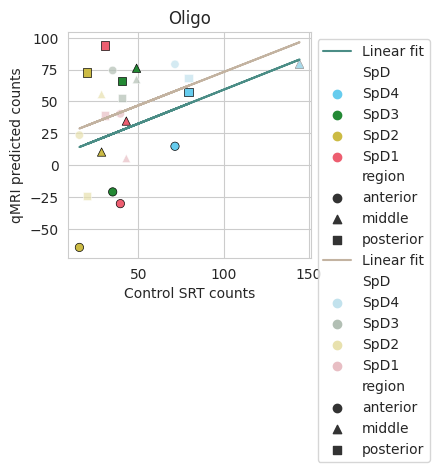

Oligo | PD beta: 0.532, CT beta: 0.525
Z-test statistic: 0.016
                            OLS Regression Results                            
Dep. Variable:       Predicted counts   R-squared:                       0.218
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     1.854
Date:                Fri, 21 Nov 2025   Prob (F-statistic):              0.170
Time:                        17:23:31   Log-Likelihood:                -120.35
No. Observations:                  24   AIC:                             248.7
Df Residuals:                      20   BIC:                             253.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

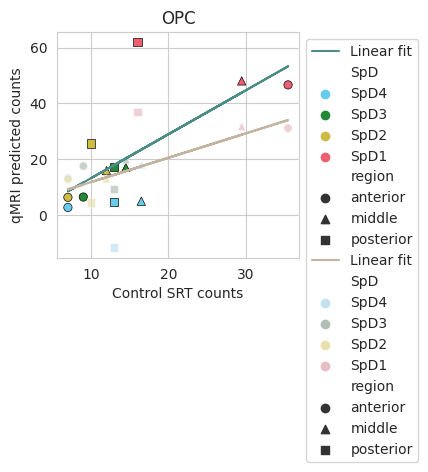

OPC | PD beta: 1.570, CT beta: 0.871
Z-test statistic: 1.067
                            OLS Regression Results                            
Dep. Variable:       Predicted counts   R-squared:                       0.442
Model:                            OLS   Adj. R-squared:                  0.359
Method:                 Least Squares   F-statistic:                     5.291
Date:                Fri, 21 Nov 2025   Prob (F-statistic):            0.00753
Time:                        17:23:32   Log-Likelihood:                -94.197
No. Observations:                  24   AIC:                             196.4
Df Residuals:                      20   BIC:                             201.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

In [38]:
custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")
pvals = []
for cell in combined_PD['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df_PD = combined_PD[combined_PD['celltype'] == cell]
    Y_PD = np.asarray(df_PD["PD - predicted counts"]).reshape(-1, 1)
    X_PD = np.asarray(df_PD["Control - real counts"]).reshape(-1, 1)
 
    df_CT = combined_CT[combined_CT['celltype'] == cell]
    Y_CT = np.asarray(df_CT["Control - predicted counts"]).reshape(-1, 1)
    X_CT = np.asarray(df_CT["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model_PD = LinearRegression().fit(X_PD, Y_PD)
    
    model_CT = LinearRegression().fit(X_CT, Y_CT)
    
    # Add intercept
    #X_sm = sm.add_constant(X)
    #sm_model = sm.OLS(Y, X_sm).fit()

    
    # Plot
    plt.figure(figsize=(4.5, 4))
    plt.plot(X_PD, model_PD.predict(X_PD), color='#4B8D86', label='Linear fit')
    ax1 = sns.scatterplot(y=df_PD["PD - predicted counts"], x=df_PD["Control - real counts"], hue=df_PD["SpD"], palette = custom_palette, style=df_PD["region"], markers=marker_dict, edgecolor='black')
    plt.plot(X_CT, model_CT.predict(X_CT), color='#C3B3A1', label='Linear fit')
    ax2 = sns.scatterplot(y=df_CT["Control - predicted counts"], x=df_CT["Control - real counts"], hue=df_CT["SpD"], palette = custom_palette_CT, style=df_CT["region"], markers=marker_dict, alpha = 0.7, facecolors='None')

    #plt.plot(X_PD, model_PD.predict(X_PD), color='darkgrey', label='Linear fit')
    #ax1 = sns.scatterplot(y=df_PD["PD - predicted counts"], x=df_PD["Control - real counts"], hue=df_PD["SpD"], palette = custom_palette, style=df_PD["region"], markers=marker_dict)
    #plt.plot(X_CT, model_CT.predict(X_CT), color='lightgrey', label='Linear fit')
    #ax2 = sns.scatterplot(y=df_CT["Control - predicted counts"], x=df_CT["Control - real counts"], hue=df_CT["SpD"], palette = custom_palette, style=df_CT["region"], markers=marker_dict)
    ax2.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.ylabel("qMRI predicted counts")
    plt.xlabel("Control SRT counts")
    plt.tight_layout()
    plt.savefig('../../plots/04-visualisations/%s_PDpred_v_CT_SRT.png' % cell, dpi = 300, bbox_inches = 'tight')
    plt.savefig('../../plots/04-visualisations/%s_PDpred_v_CT_SRT.pdf' % cell, bbox_inches = 'tight')
    
    plt.show()
    
    beta_PD = model_PD.coef_[0][0]
    intercept_PD = model_PD.intercept_[0]

    beta_CT = model_CT.coef_[0][0]
    intercept_CT = model_CT.intercept_[0]

    print(f"{cell} | PD beta: {beta_PD:.3f}, CT beta: {beta_CT:.3f}")
    
    
    import statsmodels.api as sm
    X_PD_sm = sm.add_constant(X_PD)
    sm_model_PD = sm.OLS(Y_PD, X_PD_sm).fit()

    X_CT_sm = sm.add_constant(X_CT)
    sm_model_CT = sm.OLS(Y_CT, X_CT_sm).fit()

    se_PD = sm_model_PD.bse[1]  # slope SE
    se_CT = sm_model_CT.bse[1]

    z = (beta_PD - beta_CT) / np.sqrt(se_PD**2 + se_CT**2)
    print(f"Z-test statistic: {z:.3f}")
    
    df_all = pd.concat([
    df_PD.assign(group="PD"),
    df_CT.assign(group="CT")
    ])

    X = sm.add_constant(df_all[["Control - real counts", "group"]])
    # Encode group as dummy variable
    df_all["group_dummy"] = (df_all["group"] == "PD").astype(int)
    X = sm.add_constant(pd.DataFrame({
        "Control_real": df_all["Control - real counts"],
        "Group": df_all["group_dummy"],
        "Interaction": df_all["Control - real counts"] * df_all["group_dummy"]
    }))
    df_all["Predicted counts"] = df_all["PD - predicted counts"].fillna(df_all["Control - predicted counts"])
    y = df_all["Predicted counts"]

    sm_model = sm.OLS(y, X).fit()
    print(sm_model.summary())
    pvals.append(sm_model.pvalues[2])

    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])

In [26]:
from statsmodels.stats.multitest import fdrcorrection as fdr

results_fit = pd.DataFrame(pvals, index = combined_PD['celltype'].unique())
results_fit['padj'] = fdr(results_fit[0], alpha=0.05, method='indep', is_sorted=False)[1]
results_fit

,0,padj
Astro,0.311141,0.720884
Micro,0.720884,0.720884
Oligo,0.618662,0.720884
OPC,0.630067,0.720884


In [29]:
fdr(results_fit[0], alpha=0.05, method='indep', is_sorted=False)



(array([False, False, False, False]),
 array([0.72088396, 0.72088396, 0.72088396, 0.72088396]))

In [ ]:
full_results.rename(columns = {0:'cell type', 1:'R2', 2:'pval'}, inplace = True)
full_results['padj'] = list(pd.DataFrame(fdr(full_results['pval'], alpha=0.05, method='indep', is_sorted=False)).T[1])
full_results.set_index('cell type', inplace = True)

In [ ]:
for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    r2_text = f"$R^2$ = {full_results.loc[cell]['R2']:.3f}"
    pval_text = f"padj = {full_results.loc[cell]['padj']:.3e}"
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["PD - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.savefig('../../plots/04-visualisations/%s_celltype_predictions_PD.png' % cell, dpi = 300, bbox_inches = 'tight')
    plt.show()
    